# 03 · Supercells, ribbons, slabs, flakes and edge states

**Goals**: zone folding, building ribbons with chosen edges, identifying edge states,
finite flakes, vacancies, disorder and magnetic fields (Hofstadter butterfly).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline

## 1. Supercells and zone folding

6 orbitals; K and K' fold onto the supercell Gamma:
[-3.  0.  0.  0.  0.  3.]


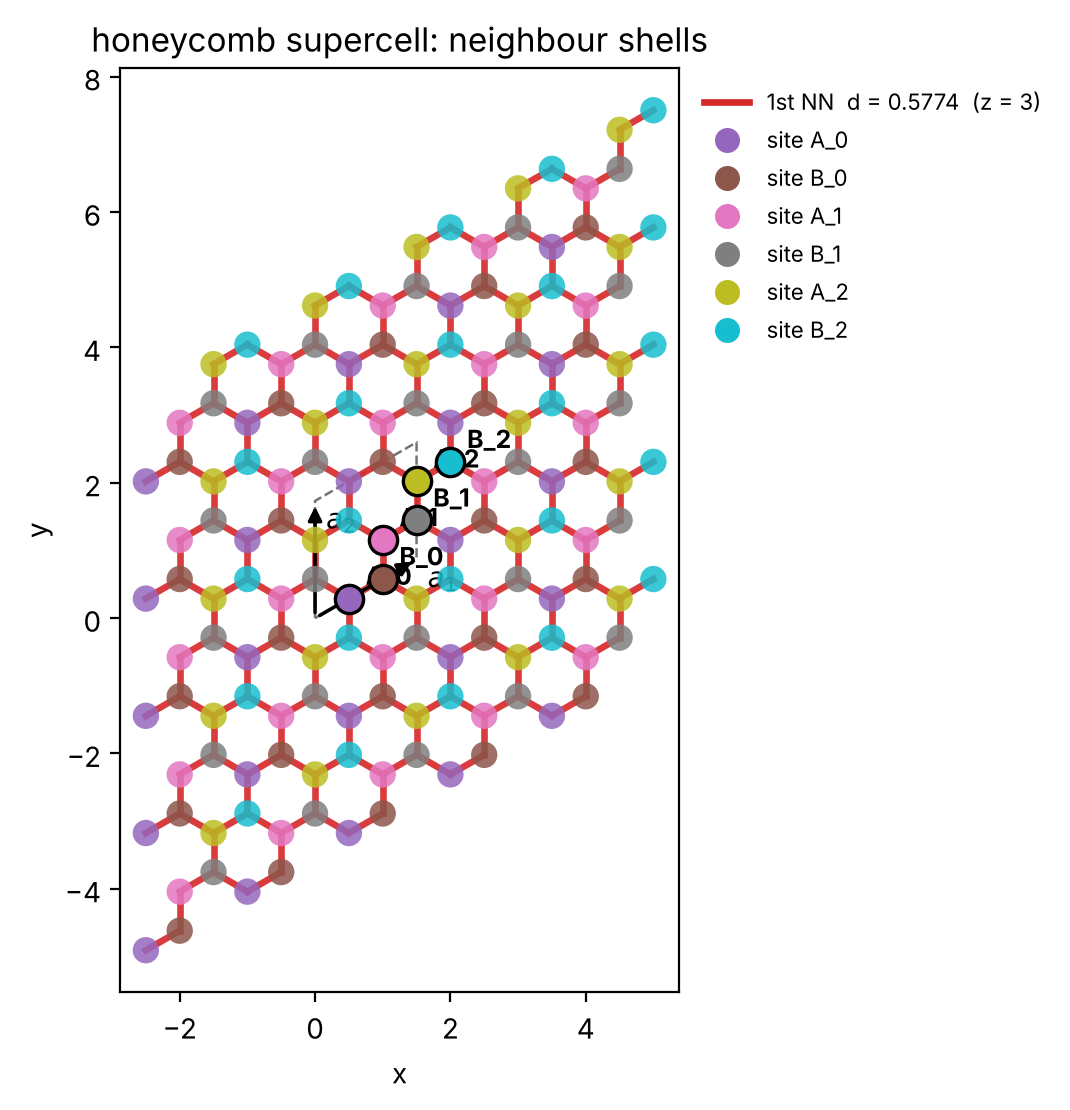

In [2]:
g = M.honeycomb()
sc = g.supercell([[1, 1], [-1, 2]])         # sqrt(3) x sqrt(3)
print(sc.norb, "orbitals; K and K' fold onto the supercell Gamma:")
print(np.round(np.sort(sc.energies(np.zeros(2))), 6))
hf.plot_lattice(sc, shells=1);

## 2. Zigzag ribbon of graphene: flat edge band
Cutting along $a_2$ keeps the zigzag direction $a_1=\hat x$ periodic.

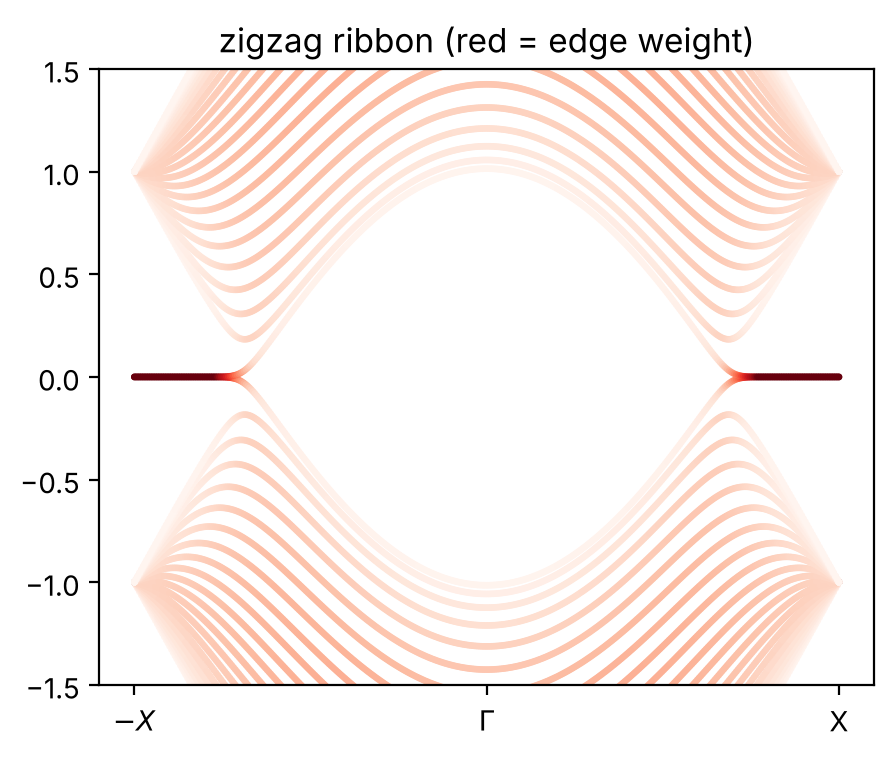

In [3]:
rib = M.honeycomb().ribbon(1, 24)
b = hf.bands(rib, ["-X", "G", "X"], n=400, vectors=True)
edge = rib.projector([0, 1, rib.norb - 2, rib.norb - 1])     # outermost orbitals
w = b.weights(edge)
fig, ax = plt.subplots(figsize=(5, 4))
for n in range(rib.nbands):
    ax.scatter(b.x, b.energies[:, n], c=w[:, n], s=2, cmap="Reds", vmin=0, vmax=0.5)
ax.set_ylim(-1.5, 1.5); ax.set_xticks(b.path.ticks); ax.set_xticklabels(b.path.labels)
ax.set_title("zigzag ribbon (red = edge weight)");

## 3. Chern insulator ribbon: chiral edge states
The Haldane bulk has $C=1$, so each edge carries one chiral mode crossing the gap.

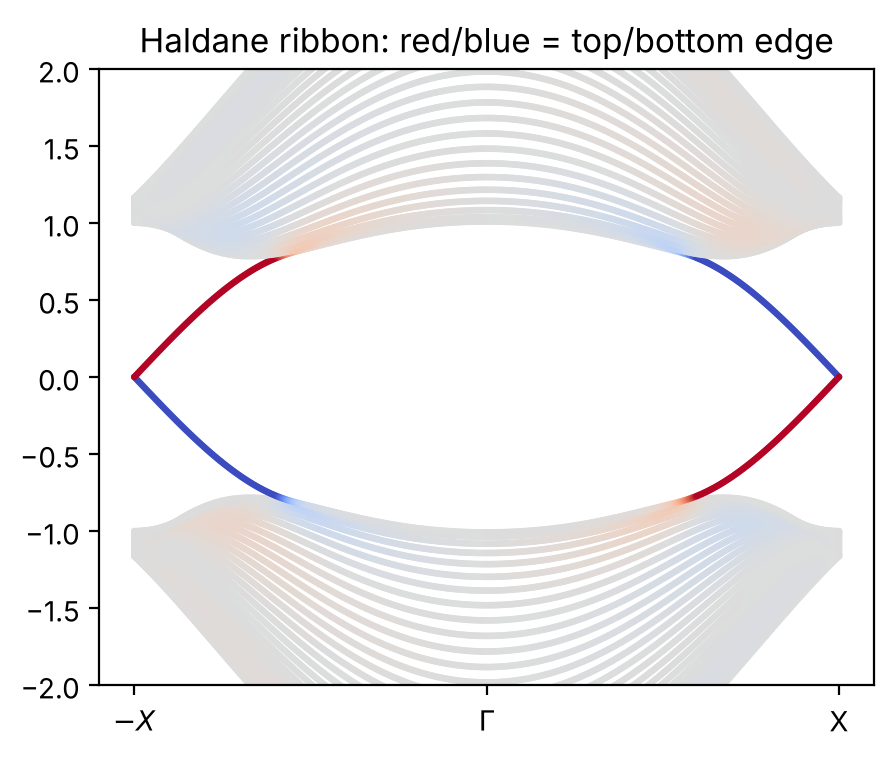

In [4]:
hr = M.haldane(t2=0.15).ribbon(1, 30)
b = hf.bands(hr, ["-X", "G", "X"], n=400, vectors=True)
top = hr.projector(list(range(hr.norb - 4, hr.norb)))
w = b.weights(top) - b.weights(hr.projector([0, 1, 2, 3]))
fig, ax = plt.subplots(figsize=(5, 4))
for n in range(hr.nbands):
    ax.scatter(b.x, b.energies[:, n], c=w[:, n], s=2, cmap="coolwarm", vmin=-0.5, vmax=0.5)
ax.set_ylim(-2, 2); ax.set_xticks(b.path.ticks); ax.set_xticklabels(b.path.labels)
ax.set_title("Haldane ribbon: red/blue = top/bottom edge");

## 4. Kane-Mele ribbon: helical edge states (QSH)

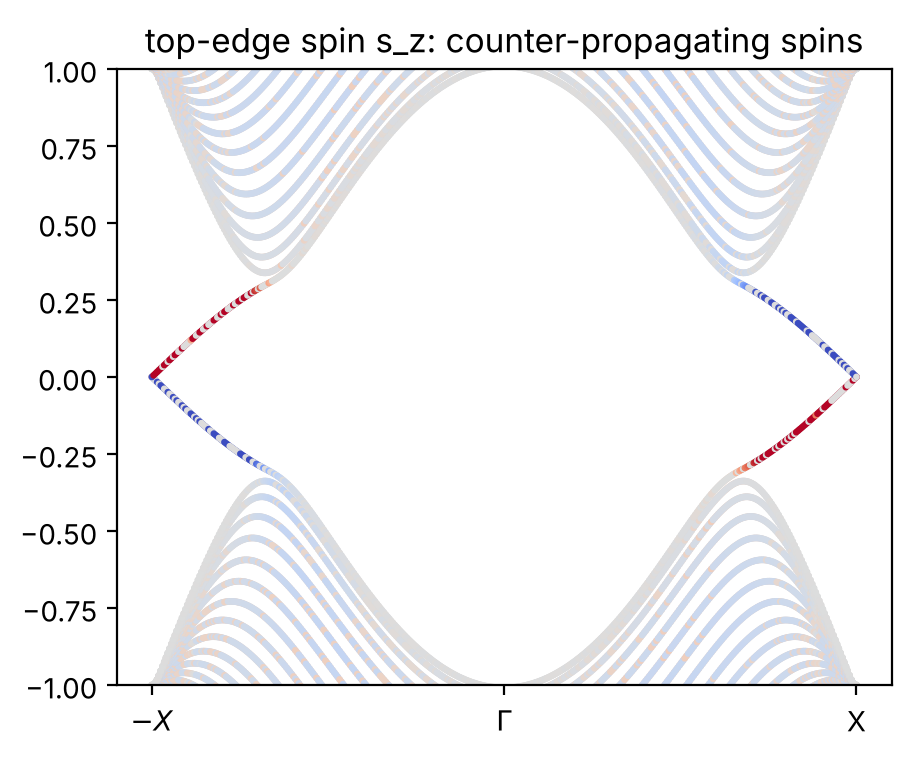

In [5]:
kr = M.kane_mele(lso=0.06).ribbon(1, 30)
b = hf.bands(kr, ["-X", "G", "X"], n=400, vectors=True)
sz_top = kr.spin_operator('z') @ kr.projector(list(range(kr.norb - 4, kr.norb)))
w = b.weights(sz_top)
fig, ax = plt.subplots(figsize=(5, 4))
for n in range(kr.nbands):
    ax.scatter(b.x, b.energies[:, n], c=w[:, n], s=2, cmap="coolwarm", vmin=-0.3, vmax=0.3)
ax.set_ylim(-1, 1); ax.set_xticks(b.path.ticks); ax.set_xticklabels(b.path.labels)
ax.set_title("top-edge spin s_z: counter-propagating spins");

## 5. Armchair ribbon: choose the edge with a supercell first

In [6]:
arm = M.honeycomb().supercell([[1, 1], [-1, 1]])      # a1' along the armchair direction
for W in (9, 10, 11):
    r = arm.ribbon(1, W)
    E = r.energies(np.linspace(-0.5, 0.5, 201))
    gap = E[:, r.nbands // 2].min() - E[:, r.nbands // 2 - 1].max()
    print(f"armchair width {W}: gap = {gap:.4f}")

armchair width 9: gap = 0.1878
armchair width 10: gap = 0.0000
armchair width 11: gap = 0.1597


## 6. Finite flakes, vacancies, disorder

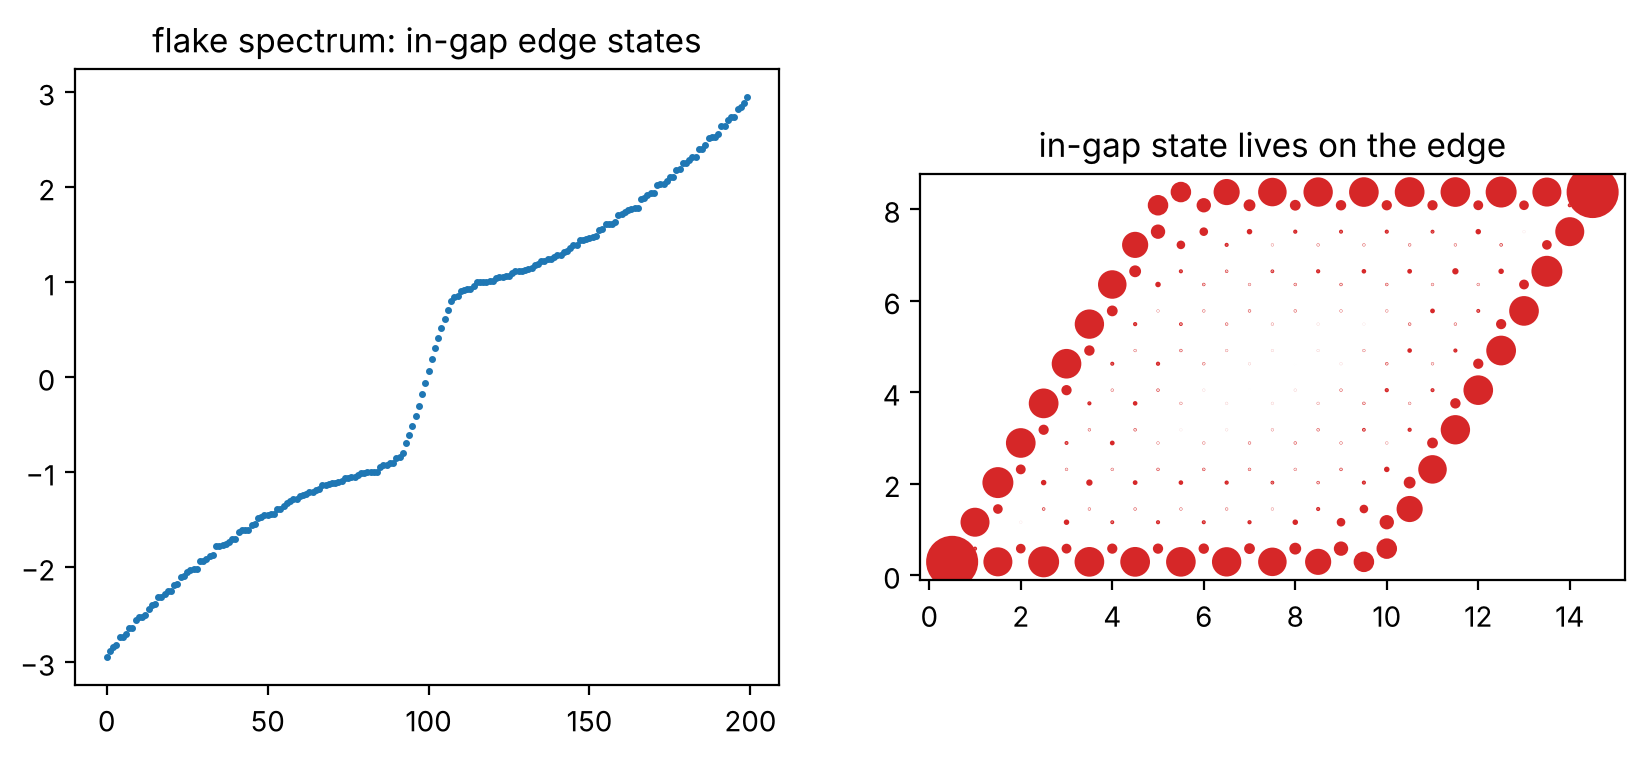

In [7]:
flake = M.haldane(t2=0.15).finite(10)
E, V = np.linalg.eigh(flake.hamiltonian())
mid = np.argmin(np.abs(E))
P = flake.lat.positions
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(E, ".", ms=3); axes[0].set_title("flake spectrum: in-gap edge states")
axes[1].scatter(P[:, 0], P[:, 1], s=4000 * np.abs(V[:, mid])**2, c="C3")
axes[1].set_aspect("equal"); axes[1].set_title("in-gap state lives on the edge");

In [8]:
sc = M.honeycomb().supercell([6, 6])
vac = sc.remove_orbitals([0])
dis = hf.add_disorder(sc, W=1.0, seed=1)
print(vac.norb, "orbitals after one vacancy;", dis.norb, "with disorder")

71 orbitals after one vacancy; 72 with disorder


## 7. Magnetic field: the Hofstadter butterfly
The Peierls phase $e^{i\int A\cdot dl}$ with flux $p/q$ per plaquette.

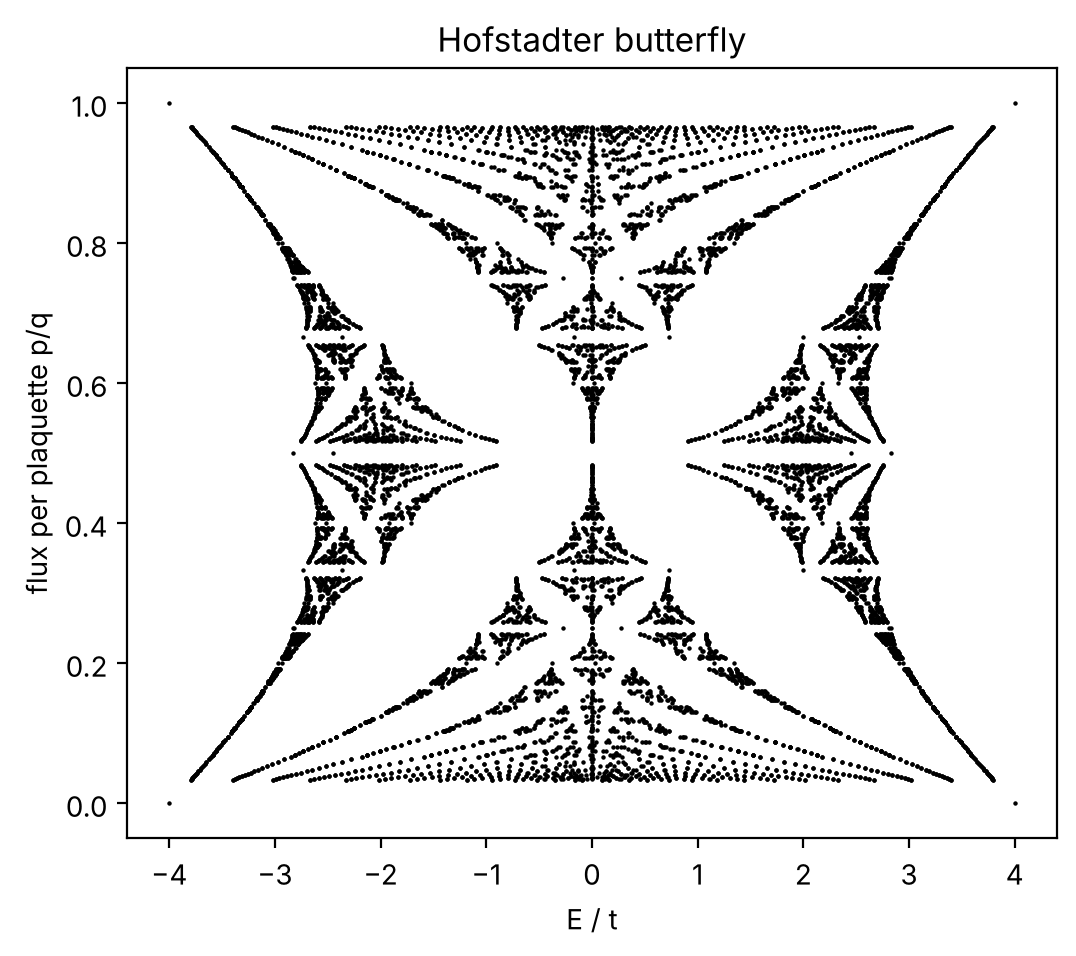

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
from math import gcd
for q in range(1, 31):
    for p in range(0, q + 1):
        if gcd(p, q) != 1: continue
        m = M.hofstadter(p, q)
        E = m.energies(np.array([[0, 0], [0.5/q, 0.5]]))
        ax.plot(E.ravel(), np.full(E.size, p / q), ".k", ms=1.2)
ax.set_xlabel("E / t"); ax.set_ylabel("flux per plaquette p/q"); ax.set_title("Hofstadter butterfly");

## Exercises
1. Plot the Fu-Kane-Mele slab (`M.diamond_fkm().slab(2, 12)`) and find the surface Dirac cones.
2. Make a disordered Haldane flake and check that the edge state survives moderate W.
3. Compute the Chern numbers of the Hofstadter bands for p/q = 1/4.

---
## Quiz 03: Supercells, ribbons and edges

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [10]:
quiz = hf.Quiz(3)
quiz.interactive()

In [11]:
quiz.show()

=== Quiz 03: Supercells, ribbons, slabs, flakes and edge states ===

Q1. A supercell with integer matrix P contains how many primitive cells?
   (a) rank(P)
   (b) sum of P
   (c) |det P|
   (d) trace(P)

Q2. In a 3x1 supercell the Brillouin zone along a1 is
   (a) 3 times smaller, bands are folded
   (b) unchanged
   (c) rotated
   (d) 3 times larger

Q3. Zone folding: the supercell Gamma point contains primitive k-points satisfying
   (a) P k = integer vector (reduced coordinates)
   (b) k = 0 only
   (c) k on the zone boundary
   (d) |k| < pi

Q4. `m.ribbon(direction=1, n=30)` on a 2D model produces
   (a) a 2D model with 30 cells
   (b) a 1D ribbon periodic along a1, 30 cells wide along a2
   (c) a 0D flake
   (d) a 3D slab

Q5. The bulk-boundary correspondence for a Chern insulator with C = 1 predicts
   (a) a gap closing in the bulk
   (b) two flat edge bands
   (c) one chiral edge mode per edge crossing the gap
   (d) no edge states

Q6. Zigzag graphene ribbons have
   (a) gappe

In [12]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0